# 0. Submission information

**Submission date:** 25 November 2026

**QPM 2026-2027: Assignment 3**

**Group members:** LOLLI Alessandro, MASTROGIACOMO Paolo, PERALDI Léandre

**Comments/challenges:** Prices are downloaded from Yahoo Finance with `yfinance` (adjusted for splits and dividends) and the monthly simple excess returns run from January 2015 to December 2022 (96 months; risk-free rate = 0). The market weights are the S&P 500 index weights reported by Investopedia, rescaled to sum to one. The main choice in the Black–Litterman model is the uncertainty of the views: we set $\tau = 1/T$ and $\Omega = \mathrm{diag}(P\,\tau\Sigma\,P^\top)$ (He and Litterman, 1999), and we explain this choice in Q1.4. All quantities are monthly unless we say "annualised". We used Claude (Anthropic) to help structure and debug the code; all results and interpretations were checked by the group.

# 1. Question 1

*In this question, we determine the optimal portfolio weights for an investor who is considering investing in an asset universe that consists of only six stocks: AAPL, MSFT, AMZN, NVDA, TSLA, and META.*

*Please download prices for these six stocks and compute their monthly simple (not log) excess returns starting January 2015 and ending December 2022 (so you need the month-end price of December 2014), assuming that the risk-free rate is 0.*

*Use the "Index Weighting" reported in this article from Investopedia to determine the market weights for these assets (you may also be able to get the market capitalizations from Yahoo Finance).*

### Setup and data

We download daily adjusted prices from 1 December 2014 to 31 December 2022, keep the last price of each month, and compute simple returns. The first return is January 2015 (it uses the month-end price of December 2014) and the last is December 2022, so we have $T = 96$ monthly observations. Because the risk-free rate is 0, these returns are also excess returns.

In [1]:
# !pip install -q yfinance        # uncomment if yfinance is not installed (e.g. in Colab)

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import display, Markdown

pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

tickers = ["AAPL", "MSFT", "AMZN", "NVDA", "TSLA", "META"]

# Daily prices adjusted for splits and dividends
daily = yf.download(tickers, start="2014-12-01", end="2023-01-01",
                    auto_adjust=True, progress=False)["Close"][tickers]

# Month-end prices (December 2014 to December 2022) and simple monthly returns
prices = daily.resample("ME").last().loc["2014-12":"2022-12"]
R = prices.pct_change().dropna()          # excess returns, since Rf = 0

assert len(R) == 96 and R.notna().all().all(), "Check the data download"
print(f"Monthly returns from {R.index[0]:%B %Y} to {R.index[-1]:%B %Y}: T = {len(R)}")
R.head()

Monthly returns from January 2015 to December 2022: T = 96


Ticker,AAPL,MSFT,AMZN,NVDA,TSLA,META
Date,,,,,,
2015-01-31,0.0614,-0.1302,0.1424,-0.0424,-0.0846,-0.0270
2015-02-28,0.1008,0.0931,0.0723,0.1534,-0.0013,0.0403
2015-03-31,-0.0314,-0.0727,-0.0212,-0.0512,-0.0717,0.0412
2015-04-30,0.0058,0.1963,0.1335,0.0607,0.1975,-0.0420
2015-05-31,0.0453,-0.0303,0.0177,0.0015,0.1095,0.0053


In [2]:
# Sample moments (monthly), used throughout the question
T = len(R)
mu = R.mean()                 # sample mean excess returns
Sigma = R.cov()               # sample covariance matrix (divides by T-1)

stats = pd.DataFrame({
    "mean (monthly)": mu,
    "std (monthly)": R.std(),
    "mean (annual)": 12 * mu,
    "std (annual)": np.sqrt(12) * R.std(),
    "Sharpe (annual)": np.sqrt(12) * mu / R.std(),
    "s.e. of mean (annual)": 12 * R.std() / np.sqrt(T),
})
display(stats.round(4))
print("Correlation matrix:")
display(R.corr().round(2))

,mean (monthly),std (monthly),mean (annual),std (annual),Sharpe (annual),s.e. of mean (annual)
Ticker,,,,,,
AAPL,0.0208,0.0841,0.2501,0.2913,0.8586,0.1030
MSFT,0.0207,0.0649,0.2488,0.2250,1.1057,0.0795
AMZN,0.0218,0.0921,0.2622,0.3192,0.8214,0.1128
NVDA,0.0450,0.1336,0.5396,0.4629,1.1657,0.1637
TSLA,0.0367,0.1811,0.4405,0.6275,0.7021,0.2219
META,0.0091,0.0946,0.1096,0.3278,0.3343,0.1159


Correlation matrix:


Ticker,AAPL,MSFT,AMZN,NVDA,TSLA,META
Ticker,,,,,,
AAPL,1.00,0.59,0.54,0.57,0.52,0.40
MSFT,0.59,1.00,0.62,0.60,0.43,0.46
AMZN,0.54,0.62,1.00,0.51,0.42,0.46
NVDA,0.57,0.60,0.51,1.00,0.32,0.35
TSLA,0.52,0.43,0.42,0.32,1.00,0.27
META,0.40,0.46,0.46,0.35,0.27,1.00


## Q1.1

*Based on the data on index weighting (or market capitalization) you have downloaded, write down the "market" weights of a portfolio that invests in only AAPL, MSFT, AMZN, NVDA, TSLA, and META. Rescale the weights so that they sum to one, because these six stocks are the whole market in this question. Then compute the market's risk aversion implied by the data, $\gamma_{mkt} = E[R_{mkt}]/V[R_{mkt}]$, where $R_{mkt}$ is the excess return on this market portfolio. Use $\gamma_{mkt}$ throughout the rest of this question.*

### Answer

We take the "Index Weighting" (percentage of the S&P 500) of each stock from the Investopedia article *Top 10 S&P 500 Stocks by Index Weight* and divide each weight by the sum of the six weights, so that the six stocks form the whole market:
$$
w_{mkt,i} = \frac{\text{index weight}_i}{\sum_{j=1}^{6}\text{index weight}_j}.
$$
The market excess return is $R_{mkt,t} = w_{mkt}^\top R_t$, and the implied risk aversion is $\gamma_{mkt} = E[R_{mkt}]/V[R_{mkt}]$, computed with the sample mean and variance of the 96 monthly returns. Since $V[R_{mkt}] = w_{mkt}^\top \Sigma\, w_{mkt}$, $\gamma_{mkt}$ is the risk aversion that makes the market portfolio the mean–variance optimal portfolio (Lecture 5).

In [3]:
# S&P 500 index weights (%) from Investopedia, "Top 10 S&P 500 Stocks by Index Weight"
# https://www.investopedia.com/top-10-s-and-p-500-stocks-by-index-weight-4843111
index_weight = pd.Series({
    "AAPL": 6.19,
    "MSFT": 4.97,
    "AMZN": 3.75,
    "NVDA": 7.08,
    "TSLA": 2.44,
    "META": 2.67,
})[tickers]

w_mkt = index_weight / index_weight.sum()      # rescaled: sums to one

R_mkt = R @ w_mkt                               # market excess return
gamma_mkt = R_mkt.mean() / R_mkt.var()          # E[R_mkt] / V[R_mkt]

display(pd.DataFrame({"index weight (%)": index_weight,
                      "market weight w_mkt": w_mkt}).round(4))
print(f"Sum of market weights: {w_mkt.sum():.4f}")
print(f"Market: mean {R_mkt.mean():.4%} per month, variance {R_mkt.var():.6f}, "
      f"volatility {R_mkt.std() * np.sqrt(12):.2%} per year")
print(f"Implied risk aversion gamma_mkt = {gamma_mkt:.4f}")

,index weight (%),market weight w_mkt
AAPL,6.19,0.2284
MSFT,4.97,0.1834
AMZN,3.75,0.1384
NVDA,7.08,0.2613
TSLA,2.44,0.0900
META,2.67,0.0985


Sum of market weights: 1.0000
Market: mean 2.7538% per month, variance 0.006370, volatility 27.65% per year
Implied risk aversion gamma_mkt = 4.3234


In [4]:
display(Markdown(
    f"**Result.** The rescaled market weights are "
    + ", ".join(f"{t} {w_mkt[t]:.1%}" for t in tickers)
    + f". The market portfolio of these six stocks earned an average excess return of "
    f"{R_mkt.mean():.2%} per month with a variance of {R_mkt.var():.5f} "
    f"(volatility {R_mkt.std() * np.sqrt(12):.1%} per year), so "
    f"$\\gamma_{{mkt}} = {R_mkt.mean():.5f}/{R_mkt.var():.5f} = {gamma_mkt:.3f}$. "
    f"This is the risk aversion of an investor for whom the market portfolio is optimal; "
    f"we use it in all the following parts."
))

**Result.** The rescaled market weights are AAPL 22.8%, MSFT 18.3%, AMZN 13.8%, NVDA 26.1%, TSLA 9.0%, META 9.9%. The market portfolio of these six stocks earned an average excess return of 2.75% per month with a variance of 0.00637 (volatility 27.6% per year), so $\gamma_{mkt} = 0.02754/0.00637 = 4.323$. This is the risk aversion of an investor for whom the market portfolio is optimal; we use it in all the following parts.

## Q1.2

*Based on the sample data on returns, compute the Markowitz mean-variance portfolio weights for $\gamma = \gamma_{mkt}$. Are these weights reasonable? Explain why.*

### Answer

With a risk-free asset (rate 0), the Markowitz portfolio of risky assets is
$$
w_{MV} = \frac{1}{\gamma_{mkt}}\,\hat\Sigma^{-1}\hat\mu ,
$$
where $\hat\mu$ and $\hat\Sigma$ are the sample mean and covariance of monthly excess returns. The weights need not sum to one: $1 - \mathbf 1^\top w_{MV}$ is invested in the risk-free asset (a negative value means borrowing).

In [5]:
w_mv = pd.Series(np.linalg.solve(Sigma, mu) / gamma_mkt, index=tickers)

out = pd.DataFrame({"Markowitz w_MV": w_mv, "market w_mkt": w_mkt})
display(out.round(4))
print(f"Sum of risky weights: {w_mv.sum():.4f}   ->   risk-free weight: {1 - w_mv.sum():.4f}")
print(f"Gross exposure sum|w|: {w_mv.abs().sum():.4f}")

,Markowitz w_MV,market w_mkt
AAPL,0.0035,0.2284
MSFT,0.6567,0.1834
AMZN,0.0565,0.1384
NVDA,0.3908,0.2613
TSLA,0.0862,0.0900
META,-0.2323,0.0985


Sum of risky weights: 0.9615   ->   risk-free weight: 0.0385
Gross exposure sum|w|: 1.4261


In [6]:
longs = w_mv[w_mv > 0].sort_values(ascending=False)
shorts = w_mv[w_mv < 0].sort_values()
txt = (f"**Result.** The Markowitz weights sum to {w_mv.sum():.2f} "
       f"(so {1 - w_mv.sum():.2f} is in the risk-free asset"
       + (", i.e. the investor borrows" if w_mv.sum() > 1 else "") + "), "
       f"and the gross exposure is {w_mv.abs().sum():.2f}. "
       f"The largest long position is {longs.index[0]} ({longs.iloc[0]:.1%}). ")
if len(shorts) > 0:
    txt += ("The portfolio is short " + ", ".join(f"{t} ({shorts[t]:.1%})" for t in shorts.index) + ". ")
else:
    txt += "There are no short positions, but the weights are very different from the market weights. "
txt += ("By comparison, the market weights are all positive, sum to one, and the largest is "
        f"{w_mkt.max():.1%}.")
display(Markdown(txt))

**Result.** The Markowitz weights sum to 0.96 (so 0.04 is in the risk-free asset), and the gross exposure is 1.43. The largest long position is MSFT (65.7%). The portfolio is short META (-23.2%). By comparison, the market weights are all positive, sum to one, and the largest is 26.1%.

**Are these weights reasonable? No.**

1. **They are extreme.** The total amount invested in risky assets is close to one, as for the market, but the *composition* is very different from the market weights: a very large position in MSFT, a large position in NVDA, almost nothing in AAPL and a short position in META, with a gross exposure well above one. By construction, an investor with risk aversion $\gamma_{mkt}$ should hold exactly the market portfolio if the market is mean–variance efficient (this is what Q1.3 uses). The Markowitz weights are very different because they use the *sample* means.
2. **They are driven by estimation error in the means.** The table of sample moments shows that, with only 96 months, the standard error of each annual mean return is large: roughly 8–22 percentage points per year (largest for NVDA and TSLA). The optimiser treats these noisy sample means as the truth. It goes long the stocks with high *past* means (e.g. NVDA, which had an exceptional 2015–2022) and short META, the stock with the lowest past mean.
3. **They are amplified by the high correlations.** The six stocks are all large technology-related firms and are strongly positively correlated. $\hat\Sigma^{-1}$ then turns small differences in means and volatilities into large bets between similar stocks. For example, AAPL and MSFT have almost the same sample mean (about 25% per year), but MSFT is less volatile, so the optimiser puts about two thirds of the wealth in MSFT and almost nothing in AAPL. TSLA has the second-highest mean but receives less than 10%, because it is so volatile. This is the "error maximisation" problem of Michaud (1989) discussed in Lecture 4.
4. **They are unstable and perform badly out of sample.** Small changes in $\hat\mu$ (e.g. a different sample period) would change these weights a lot. As we saw in Lectures 2–4, such portfolios typically have poor out-of-sample performance.

These problems are exactly the motivation for the Black–Litterman model.

*Next, we will compute the Black-Litterman portfolio weights. We will do this in four small steps.*

## Q1.3

*Step 1: Using the rescaled market weights and $\gamma_{mkt}$ from Q1.1, calculate the CAPM-implied expected returns.*

### Answer

If the market portfolio is the mean–variance portfolio of an investor with risk aversion $\gamma_{mkt}$, then $w_{mkt} = \frac{1}{\gamma_{mkt}}\Sigma^{-1}\mu_{CAPM}$. Inverting this relation (*reverse optimisation*) gives the CAPM-implied (equilibrium) expected excess returns
$$
\mu_{CAPM} = \gamma_{mkt}\,\Sigma\, w_{mkt}.
$$
We use the sample covariance matrix $\hat\Sigma$, which is estimated much more precisely than the means.

In [7]:
mu_capm = gamma_mkt * Sigma @ w_mkt

display(pd.DataFrame({
    "mu_CAPM (monthly)": mu_capm,
    "mu_CAPM (annual)": 12 * mu_capm,
    "sample mean (annual)": 12 * mu,
    "beta w.r.t. market": (Sigma @ w_mkt) / (w_mkt @ Sigma @ w_mkt),
}).round(4))

# Check: Markowitz with the CAPM-implied means gives back the market weights
w_check = np.linalg.solve(Sigma, mu_capm) / gamma_mkt
print("Markowitz weights using mu_CAPM:", np.round(w_check, 4))
print("Equal to w_mkt:", np.allclose(w_check, w_mkt))
print(f"Check: w_mkt' mu_CAPM = {w_mkt @ mu_capm:.5f} = E[R_mkt] = {R_mkt.mean():.5f}")

,mu_CAPM (monthly),mu_CAPM (annual),sample mean (annual),beta w.r.t. market
Ticker,,,,
AAPL,0.0237,0.2845,0.2501,0.8608
MSFT,0.0177,0.2129,0.2488,0.6443
AMZN,0.0237,0.2846,0.2622,0.8613
NVDA,0.0392,0.4704,0.5396,1.4233
TSLA,0.0394,0.4725,0.4405,1.4299
META,0.0183,0.2195,0.1096,0.6643


Markowitz weights using mu_CAPM: [0.2284 0.1834 0.1384 0.2613 0.09   0.0985]
Equal to w_mkt: True
Check: w_mkt' mu_CAPM = 0.02754 = E[R_mkt] = 0.02754


In [8]:
display(Markdown(
    "**Result.** The CAPM-implied expected excess returns (annualised) are "
    + ", ".join(f"{t} {12 * mu_capm[t]:.1%}" for t in tickers)
    + f". They range from {12 * mu_capm.min():.1%} to {12 * mu_capm.max():.1%} per year, "
    f"a much narrower range than the sample means "
    f"({12 * mu.min():.1%} to {12 * mu.max():.1%}). "
    "Each stock's CAPM return is proportional to its covariance with the market, "
    "$\\mu_{CAPM,i} = \\beta_i\\,E[R_{mkt}]$, so high-beta stocks (e.g. TSLA, NVDA) have higher expected returns. "
    "As a check, using $\\mu_{CAPM}$ in the Markowitz formula gives back exactly the market weights, "
    "and the market's CAPM expected return equals its sample mean."
))

**Result.** The CAPM-implied expected excess returns (annualised) are AAPL 28.4%, MSFT 21.3%, AMZN 28.5%, NVDA 47.0%, TSLA 47.3%, META 22.0%. They range from 21.3% to 47.3% per year, a much narrower range than the sample means (11.0% to 54.0%). Each stock's CAPM return is proportional to its covariance with the market, $\mu_{CAPM,i} = \beta_i\,E[R_{mkt}]$, so high-beta stocks (e.g. TSLA, NVDA) have higher expected returns. As a check, using $\mu_{CAPM}$ in the Markowitz formula gives back exactly the market weights, and the market's CAPM expected return equals its sample mean.

## Q1.4

*Step 2: Specify the pick matrix $P$ and the view vector $q$ that captures the following views for each of the assets:*
- *AAPL: its absolute excess return is expected to be 10% per year.*
- *MSFT: its absolute excess return is expected to be 5% per year.*
- *AMZN: no views*
- *NVDA will outperform TSLA by 2% per year.*
- *TSLA will underperform META by 1% per year (that is, META − TSLA = 1%).*

*Convert the views to monthly terms before you use them, because the returns are monthly.*
*Finally, explain your choice for the matrix $\Omega$, which captures the uncertainty about these views. (There are different ways to specify this matrix, so feel free to choose anything reasonable.)*

### Answer

**Views.** With the assets ordered as (AAPL, MSFT, AMZN, NVDA, TSLA, META), we have $K = 4$ views, $P\mu = q + \varepsilon_q$ with $\varepsilon_q \sim N(0, \Omega)$:
$$
P = \begin{pmatrix}
1 & 0 & 0 & 0 & 0 & 0\\
0 & 1 & 0 & 0 & 0 & 0\\
0 & 0 & 0 & 1 & -1 & 0\\
0 & 0 & 0 & 0 & -1 & 1
\end{pmatrix},
\qquad
q = \frac{1}{12}\begin{pmatrix}0.10\\0.05\\0.02\\0.01\end{pmatrix}
= \begin{pmatrix}0.00833\\0.00417\\0.00167\\0.00083\end{pmatrix}.
$$
- Rows 1 and 2 are **absolute** views (a single 1).
- Rows 3 and 4 are **relative** views: each row sums to zero (a long–short portfolio). Row 4 is written as META − TSLA = 1%, as in the question.
- **AMZN has no view**, so its column of $P$ is all zeros.
- We convert the annual views to monthly by dividing by 12, consistent with the monthly means.

**Choice of $\Omega$.** We follow He and Litterman (1999), as in Lecture 5:
$$
V_\mu = \tau\Sigma,\quad \tau = \frac{1}{T} = \frac{1}{96},\qquad
\Omega = \mathrm{diag}\big(P\,(\tau\Sigma)\,P^\top\big).
$$
- $\tau = 1/T$: the uncertainty about the mean, $\tau\Sigma$, is the variance of a sample mean estimated from $T = 96$ months.
- The variance of each view equals the variance of the *portfolio the view is about* (row $k$ of $P$), scaled by $\tau$. Views on volatile stocks or volatile long–short portfolios are therefore less certain. For example, the view on NVDA − TSLA, two very volatile stocks, is less precise than the view on MSFT.
- With this choice, the investor is as confident in each view as in the CAPM prior for that portfolio. For a single view, the posterior would put a weight of exactly 50% on the view and 50% on the CAPM.
- $\Omega$ is diagonal: the errors in different views are independent.
- With $\Omega \propto \tau$, the value of $\tau$ cancels out of $\mu_{BL}$ (Lecture 5), so the posterior means do not depend on the exact choice of $\tau$.

Other reasonable choices would be the Idzorek (2007) method, which specifies a confidence level in % for each view, or a scalar multiple of the He–Litterman $\Omega$ to make the investor more or less confident.

In [9]:
assets = tickers                                    # AAPL, MSFT, AMZN, NVDA, TSLA, META
views = ["AAPL = 10%", "MSFT = 5%", "NVDA - TSLA = 2%", "META - TSLA = 1%"]

P = pd.DataFrame([[1, 0, 0, 0,  0, 0],
                  [0, 1, 0, 0,  0, 0],
                  [0, 0, 0, 1, -1, 0],
                  [0, 0, 0, 0, -1, 1]], index=views, columns=assets, dtype=float)
q_annual = pd.Series([0.10, 0.05, 0.02, 0.01], index=views)
q = q_annual / 12                                   # monthly views

tau = 1 / T
Omega = pd.DataFrame(np.diag(np.diag(P @ (tau * Sigma) @ P.T)), index=views, columns=views)

print("Pick matrix P:"); display(P)
print("Views q (monthly):"); display(q.round(5))
print(f"tau = 1/T = {tau:.5f}")
print("Omega = diag(P tau Sigma P'):")
with pd.option_context("display.precision", 6):
    display(Omega.round(6))

Pick matrix P:


,AAPL,MSFT,AMZN,NVDA,TSLA,META
AAPL = 10%,1.0,0.0,0.0,0.0,0.0,0.0
MSFT = 5%,0.0,1.0,0.0,0.0,0.0,0.0
NVDA - TSLA = 2%,0.0,0.0,0.0,1.0,-1.0,0.0
META - TSLA = 1%,0.0,0.0,0.0,0.0,-1.0,1.0


Views q (monthly):


AAPL = 10%          0.0083
MSFT = 5%           0.0042
NVDA - TSLA = 2%    0.0017
META - TSLA = 1%    0.0008
dtype: float64

tau = 1/T = 0.01042
Omega = diag(P tau Sigma P'):


,AAPL = 10%,MSFT = 5%,NVDA - TSLA = 2%,META - TSLA = 1%
AAPL = 10%,0.000074,0.000000,0.000000,0.00000
MSFT = 5%,0.000000,0.000044,0.000000,0.00000
NVDA - TSLA = 2%,0.000000,0.000000,0.000369,0.00000
META - TSLA = 1%,0.000000,0.000000,0.000000,0.00034


In [10]:
# How different are the views from what the CAPM already implies?
cmp = pd.DataFrame({
    "view q (annual)": q_annual,
    "CAPM-implied P mu_CAPM (annual)": 12 * (P @ mu_capm),
    "view - CAPM (annual)": q_annual - 12 * (P @ mu_capm),
    "std of view (annual)": 12 * np.sqrt(np.diag(Omega)),
})
display(cmp.round(4))

,view q (annual),CAPM-implied P mu_CAPM (annual),view - CAPM (annual),std of view (annual)
AAPL = 10%,0.10,0.2845,-0.1845,0.1030
MSFT = 5%,0.05,0.2129,-0.1629,0.0795
NVDA - TSLA = 2%,0.02,-0.0022,0.0222,0.2304
META - TSLA = 1%,0.01,-0.2530,0.2630,0.2213


In [11]:
diff = q_annual - 12 * (P @ mu_capm)
display(Markdown(
    "**Views relative to the CAPM.** The table compares each view with what the CAPM already implies for the same portfolio: "
    + "; ".join(f"{v}: the CAPM implies {12 * (P @ mu_capm)[v]:.1%}, so the view is "
                f"{'more optimistic' if diff[v] > 0 else 'more pessimistic'} by {abs(diff[v]):.1%}"
                for v in views)
    + ". Black–Litterman moves the expected returns from the CAPM values towards these views. "
    "Because the views share assets (TSLA appears in both relative views), they also affect each other, "
    "so the posterior for one view need not lie between the CAPM value and the view (see Q1.5)."
))

**Views relative to the CAPM.** The table compares each view with what the CAPM already implies for the same portfolio: AAPL = 10%: the CAPM implies 28.4%, so the view is more pessimistic by 18.4%; MSFT = 5%: the CAPM implies 21.3%, so the view is more pessimistic by 16.3%; NVDA - TSLA = 2%: the CAPM implies -0.2%, so the view is more optimistic by 2.2%; META - TSLA = 1%: the CAPM implies -25.3%, so the view is more optimistic by 26.3%. Black–Litterman moves the expected returns from the CAPM values towards these views. Because the views share assets (TSLA appears in both relative views), they also affect each other, so the posterior for one view need not lie between the CAPM value and the view (see Q1.5).

## Q1.5

*Step 3: Use these views to compute the conditional expected excess returns ($\mu_{BL}$) and covariance matrix of excess returns ($\Sigma_{BL}$).*

### Answer

The posterior (Black–Litterman) moments are (Lecture 5, equations (10)–(11)):
$$
\mu_{BL} = \big[(\tau\Sigma)^{-1} + P^\top\Omega^{-1}P\big]^{-1}\big[(\tau\Sigma)^{-1}\mu_{CAPM} + P^\top\Omega^{-1}q\big],
$$
$$
\Sigma_{BL} = \Sigma + \big[(\tau\Sigma)^{-1} + P^\top\Omega^{-1}P\big]^{-1}.
$$
$\mu_{BL}$ is a precision-weighted average of the CAPM-implied returns and the views. $\Sigma_{BL}$ adds to $\Sigma$ the remaining uncertainty about the mean. We also check $\mu_{BL}$ with the equivalent "regression" form, $\mu_{BL} = \mu_{CAPM} + \tau\Sigma P^\top (P\tau\Sigma P^\top + \Omega)^{-1}(q - P\mu_{CAPM})$.

In [12]:
S = Sigma.values
tS_inv = np.linalg.inv(tau * S)
O_inv = np.linalg.inv(Omega.values)
Pm = P.values

M = tS_inv + Pm.T @ O_inv @ Pm                     # posterior precision of mu
M_inv = np.linalg.inv(M)

mu_bl = pd.Series(M_inv @ (tS_inv @ mu_capm.values + Pm.T @ O_inv @ q.values), index=tickers)
Sigma_bl = pd.DataFrame(S + M_inv, index=tickers, columns=tickers)

# Check with the "regression" form of the posterior mean
mu_bl_2 = mu_capm.values + tau * S @ Pm.T @ np.linalg.solve(Pm @ (tau * S) @ Pm.T + Omega.values,
                                                            q.values - Pm @ mu_capm.values)
print("Both formulas give the same mu_BL:", np.allclose(mu_bl, mu_bl_2))

display(pd.DataFrame({
    "mu_CAPM (annual)": 12 * mu_capm,
    "mu_BL (annual)": 12 * mu_bl,
    "change (annual)": 12 * (mu_bl - mu_capm),
    "sample mean (annual)": 12 * mu,
}).round(4))
print("Sigma_BL (monthly):")
with pd.option_context("display.precision", 5):
    display(Sigma_bl.round(5))
print(f"Sigma_BL / Sigma on the diagonal (= 1 + tau = {1 + tau:.4f} with no views):")
display((np.diag(Sigma_bl) / np.diag(S)).round(4))
print("Implied views after updating, P mu_BL (annual):")
display((12 * (P @ mu_bl)).round(4))

Both formulas give the same mu_BL: True


,mu_CAPM (annual),mu_BL (annual),change (annual),sample mean (annual)
AAPL,0.2845,0.1609,-0.1236,0.2501
MSFT,0.2129,0.1140,-0.0989,0.2488
AMZN,0.2846,0.1835,-0.1012,0.2622
NVDA,0.4704,0.3160,-0.1544,0.5396
TSLA,0.4725,0.2605,-0.2120,0.4405
META,0.2195,0.1642,-0.0554,0.1096


Sigma_BL (monthly):


,AAPL,MSFT,AMZN,NVDA,TSLA,META
AAPL,0.00710,0.00321,0.00422,0.00641,0.00801,0.00316
MSFT,0.00321,0.00424,0.00372,0.00520,0.00507,0.00283
AMZN,0.00422,0.00372,0.00855,0.00634,0.00696,0.00407
NVDA,0.00641,0.00520,0.00634,0.01797,0.00769,0.00440
TSLA,0.00801,0.00507,0.00696,0.00769,0.03295,0.00459
META,0.00316,0.00283,0.00407,0.00440,0.00459,0.00903


Sigma_BL / Sigma on the diagonal (= 1 + tau = 1.0104 with no views):


array([1.0046, 1.0047, 1.0077, 1.0065, 1.0043, 1.0082])

Implied views after updating, P mu_BL (annual):


AAPL = 10%          0.1609
MSFT = 5%           0.1140
NVDA - TSLA = 2%    0.0555
META - TSLA = 1%   -0.0963
dtype: float64

In [13]:
chg = mu_bl - mu_capm
capm_v, post_v = P @ mu_capm, P @ mu_bl
between = [v for v in views if min(capm_v[v], q[v]) <= post_v[v] <= max(capm_v[v], q[v])]
outside = [v for v in views if v not in between]

txt = ("**Result.** Annualised, the Black–Litterman expected excess returns are "
       + ", ".join(f"{t} {12 * mu_bl[t]:.1%}" for t in tickers)
       + ". Compared with the CAPM: "
       + ", ".join(f"{t} {12 * chg[t]:+.1%}" for t in tickers) + ". ")
txt += ("$\\mu_{BL}$ is a precision-weighted average of the CAPM and the views. "
        "For " + ", ".join(between) + ", the updated value $P\\mu_{BL}$ lies between the CAPM value and the view: "
        "the views pull the expected returns part of the way, not all the way. ")
for v in outside:
    txt += (f"The exception is {v}: the CAPM implies {12 * capm_v[v]:.1%} and the view is {12 * q[v]:.1%}, "
            f"but the posterior is {12 * post_v[v]:.1%}, beyond the view. ")
if outside:
    txt += ("This happens because the views are not independent. TSLA appears in both relative views, and the "
            f"META − TSLA view is far above the CAPM ({12 * capm_v['META - TSLA = 1%']:.1%} vs {12 * q['META - TSLA = 1%']:.1%}), "
            f"so TSLA's expected return falls a lot ({12 * chg['TSLA']:+.1%}), more than NVDA's ({12 * chg['NVDA']:+.1%}). "
            "This pushes NVDA − TSLA above its own view. With several overlapping views, each view also moves "
            "the other views' portfolios. ")
txt += (f"AMZN has no view, but its expected return still changes ({12 * chg['AMZN']:+.1%} per year), "
        "because AMZN is correlated with the stocks in the views and the views carry information about it. "
        "The posterior covariance $\\Sigma_{BL}$ is slightly larger than $\\Sigma$ "
        f"(the diagonal is between {np.min(np.diag(Sigma_bl) / np.diag(S)):.4f} and {np.max(np.diag(Sigma_bl) / np.diag(S)):.4f} times the sample variances): "
        "it adds the uncertainty about the mean, which the views reduce relative to the no-view case $(1+\\tau)\\Sigma$.")
display(Markdown(txt))

**Result.** Annualised, the Black–Litterman expected excess returns are AAPL 16.1%, MSFT 11.4%, AMZN 18.3%, NVDA 31.6%, TSLA 26.0%, META 16.4%. Compared with the CAPM: AAPL -12.4%, MSFT -9.9%, AMZN -10.1%, NVDA -15.4%, TSLA -21.2%, META -5.5%. $\mu_{BL}$ is a precision-weighted average of the CAPM and the views. For AAPL = 10%, MSFT = 5%, META - TSLA = 1%, the updated value $P\mu_{BL}$ lies between the CAPM value and the view: the views pull the expected returns part of the way, not all the way. The exception is NVDA - TSLA = 2%: the CAPM implies -0.2% and the view is 2.0%, but the posterior is 5.5%, beyond the view. This happens because the views are not independent. TSLA appears in both relative views, and the META − TSLA view is far above the CAPM (-25.3% vs 1.0%), so TSLA's expected return falls a lot (-21.2%), more than NVDA's (-15.4%). This pushes NVDA − TSLA above its own view. With several overlapping views, each view also moves the other views' portfolios. AMZN has no view, but its expected return still changes (-10.1% per year), because AMZN is correlated with the stocks in the views and the views carry information about it. The posterior covariance $\Sigma_{BL}$ is slightly larger than $\Sigma$ (the diagonal is between 1.0043 and 1.0082 times the sample variances): it adds the uncertainty about the mean, which the views reduce relative to the no-view case $(1+\tau)\Sigma$.

## Q1.6

*Step 4: Now, use $\mu_{BL}$ and $\Sigma_{BL}$ to compute the Black-Litterman mean-variance weights.*

### Answer

We use the posterior moments in the Markowitz formula with the same risk aversion:
$$
w_{BL} = \frac{1}{\gamma_{mkt}}\,\Sigma_{BL}^{-1}\,\mu_{BL}.
$$
Following He and Litterman (1999), these weights can also be written as $w_{BL} = \frac{1}{1+\tau}\big(w_{mkt} + P^\top\Lambda\big)$. Without views, the investor holds $w_{mkt}/(1+\tau)$. The views tilt this portfolio **only for the assets that appear in the views**, in proportion to the rows of $P$.

In [14]:
w_bl = pd.Series(np.linalg.solve(Sigma_bl, mu_bl) / gamma_mkt, index=tickers)
w_noview = w_mkt / (1 + tau)
tilt = w_bl - w_noview

# Lambda from the He-Litterman decomposition: (1+tau) * tilt = P' Lambda
Lam = pd.Series(np.linalg.lstsq(Pm.T, (1 + tau) * tilt.values, rcond=None)[0], index=views)

display(pd.DataFrame({"w_BL": w_bl, "w_mkt/(1+tau)": w_noview, "tilt": tilt, "w_mkt": w_mkt}).round(4))
print(f"Sum of BL weights: {w_bl.sum():.4f}   ->   risk-free weight: {1 - w_bl.sum():.4f}")
print(f"Tilt on AMZN (no view): {tilt['AMZN']:.2e}")
print("Lambda (one per view):"); display(Lam.round(4))
print("Check (1+tau)*tilt = P' Lambda:", np.allclose((1 + tau) * tilt.values, Pm.T @ Lam.values))

,w_BL,w_mkt/(1+tau),tilt,w_mkt
AAPL,0.0637,0.2261,-0.1624,0.2284
MSFT,-0.1059,0.1815,-0.2874,0.1834
AMZN,0.1369,0.1369,0.0000,0.1384
NVDA,0.2397,0.2586,-0.0189,0.2613
TSLA,0.0461,0.0891,-0.0430,0.0900
META,0.1594,0.0975,0.0619,0.0985


Sum of BL weights: 0.5399   ->   risk-free weight: 0.4601
Tilt on AMZN (no view): 5.55e-17
Lambda (one per view):


AAPL = 10%         -0.1641
MSFT = 5%          -0.2904
NVDA - TSLA = 2%   -0.0191
META - TSLA = 1%    0.0625
dtype: float64

Check (1+tau)*tilt = P' Lambda: True


In [15]:
display(Markdown(
    "**Result.** The Black–Litterman weights are "
    + ", ".join(f"{t} {w_bl[t]:.1%}" for t in tickers)
    + f", summing to {w_bl.sum():.3f} (the rest, {1 - w_bl.sum():.3f}, is in the risk-free asset). "
    "Relative to the no-view portfolio $w_{mkt}/(1+\\tau)$, the tilts are "
    + ", ".join(f"{t} {tilt[t]:+.1%}" for t in tickers)
    + ". As predicted by He and Litterman (1999), **AMZN's weight does not change** "
    f"(tilt {tilt['AMZN']:.1e}, i.e. zero) even though its expected return changed in Q1.5: "
    "the optimiser already accounts for its correlation with the other stocks through $\\Sigma$. "
    + " ".join(f"The view on {t} is {'below' if diff.iloc[i] < 0 else 'above'} the CAPM-implied return and its weight "
               f"{'falls' if tilt[t] < 0 else 'rises'} ({tilt[t]:+.1%})"
               + (f", so that {t} becomes a short position ({w_bl[t]:.1%})." if w_bl[t] < 0 else ".")
               for i, t in enumerate(["AAPL", "MSFT"]))
    + f" TSLA appears in both relative views, so its tilt is $-(\\Lambda_3+\\Lambda_4)/(1+\\tau)$ = {tilt['TSLA']:+.1%}, "
    f"while NVDA receives $\\Lambda_3/(1+\\tau)$ = {tilt['NVDA']:+.1%} and META $\\Lambda_4/(1+\\tau)$ = {tilt['META']:+.1%}. "
    + "".join(f"Note that $\\Lambda$ for {v} is {'negative' if Lam[v] < 0 else 'positive'} although this view is "
              f"{'above' if diff[v] > 0 else 'below'} the CAPM: with overlapping views the tilts are set jointly, "
              "and as shown in Q1.5 the other views already push this portfolio beyond the view, "
              "so the optimiser slightly reduces this bet. "
              for v in views if np.sign(Lam[v]) != np.sign(diff[v]))
    + (f"Overall, the BL weights sum to less than one: the views are on average less optimistic than the CAPM, "
       f"so the investor holds less in the risky assets and {1 - w_bl.sum():.1%} in the risk-free asset."
       if w_bl.sum() < 1 else
       f"Overall, the BL weights sum to more than one, so the investor borrows {w_bl.sum() - 1:.1%} at the risk-free rate.")
))

**Result.** The Black–Litterman weights are AAPL 6.4%, MSFT -10.6%, AMZN 13.7%, NVDA 24.0%, TSLA 4.6%, META 15.9%, summing to 0.540 (the rest, 0.460, is in the risk-free asset). Relative to the no-view portfolio $w_{mkt}/(1+\tau)$, the tilts are AAPL -16.2%, MSFT -28.7%, AMZN +0.0%, NVDA -1.9%, TSLA -4.3%, META +6.2%. As predicted by He and Litterman (1999), **AMZN's weight does not change** (tilt 5.6e-17, i.e. zero) even though its expected return changed in Q1.5: the optimiser already accounts for its correlation with the other stocks through $\Sigma$. The view on AAPL is below the CAPM-implied return and its weight falls (-16.2%). The view on MSFT is below the CAPM-implied return and its weight falls (-28.7%), so that MSFT becomes a short position (-10.6%). TSLA appears in both relative views, so its tilt is $-(\Lambda_3+\Lambda_4)/(1+\tau)$ = -4.3%, while NVDA receives $\Lambda_3/(1+\tau)$ = -1.9% and META $\Lambda_4/(1+\tau)$ = +6.2%. Note that $\Lambda$ for NVDA - TSLA = 2% is negative although this view is above the CAPM: with overlapping views the tilts are set jointly, and as shown in Q1.5 the other views already push this portfolio beyond the view, so the optimiser slightly reduces this bet. Overall, the BL weights sum to less than one: the views are on average less optimistic than the CAPM, so the investor holds less in the risky assets and 46.0% in the risk-free asset.

## Q1.7

*Finally, compare the three sets of portfolio weights you have computed:*
- *Markowitz mean-variance portfolio weights;*
- *Capitalization-weighted (market) portfolio weights;*
- *Black-Litterman mean-variance portfolio weights.*

*Which weights seem the most reasonable? Why?*

,Markowitz,Market (cap-weighted),Black-Litterman
AAPL,0.0035,0.2284,0.0637
MSFT,0.6567,0.1834,-0.1059
AMZN,0.0565,0.1384,0.1369
NVDA,0.3908,0.2613,0.2397
TSLA,0.0862,0.0900,0.0461
META,-0.2323,0.0985,0.1594


,Markowitz,Market (cap-weighted),Black-Litterman
sum of risky weights,0.9615,1.0000,0.5399
risk-free weight,0.0385,0.0000,0.4601
gross exposure sum|w|,1.4261,1.0000,0.7517
number of short positions,1.0000,0.0000,1.0000
largest |weight|,0.6567,0.2613,0.2397
distance from market sum|w - w_mkt|,1.2442,0.0000,0.5818


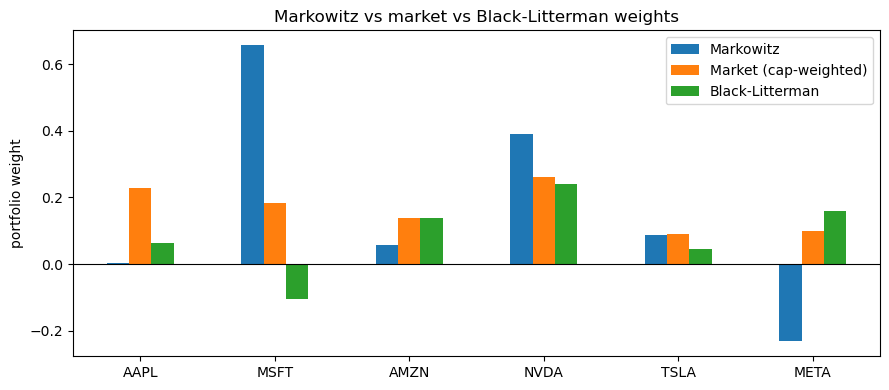

In [16]:
W = pd.DataFrame({"Markowitz": w_mv, "Market (cap-weighted)": w_mkt, "Black-Litterman": w_bl})

def describe(w):
    return pd.Series({
        "sum of risky weights": w.sum(),
        "risk-free weight": 1 - w.sum(),
        "gross exposure sum|w|": w.abs().sum(),
        "number of short positions": int((w < 0).sum()),
        "largest |weight|": w.abs().max(),
        "distance from market sum|w - w_mkt|": (w - w_mkt).abs().sum(),
    })

summary = W.apply(describe)
display(W.round(4))
display(summary.round(4))

ax = W.plot.bar(figsize=(9, 4), rot=0)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("portfolio weight")
ax.set_title("Markowitz vs market vs Black-Litterman weights")
plt.tight_layout()
plt.show()

In [17]:
# Ex-ante annual Sharpe ratios of the three portfolios under different beliefs about the means
def sharpe(w, m, V):
    return np.sqrt(12) * (w @ m) / np.sqrt(w @ V @ w)

sr = pd.DataFrame({name: {"using sample means": sharpe(w, mu, Sigma),
                          "using CAPM means": sharpe(w, mu_capm, Sigma),
                          "using BL means": sharpe(w, mu_bl, Sigma_bl)}
                   for name, w in W.items()})
display(sr.round(3))

,Markowitz,Market (cap-weighted),Black-Litterman
using sample means,1.319,1.195,1.085
using CAPM means,1.083,1.195,1.149
using BL means,0.633,0.740,0.770


In [18]:
display(Markdown(
    f"**Comparison.** The Markowitz portfolio has a gross exposure of {w_mv.abs().sum():.2f}, "
    f"{int((w_mv < 0).sum())} short position(s) and a largest absolute weight of {w_mv.abs().max():.1%}. "
    f"Its distance from the market portfolio is {(w_mv - w_mkt).abs().sum():.2f}. "
    f"The Black–Litterman portfolio has a gross exposure of {w_bl.abs().sum():.2f}, "
    f"{int((w_bl < 0).sum())} short position(s), a largest weight of {w_bl.abs().max():.1%}, "
    f"and a distance from the market of only {(w_bl - w_mkt).abs().sum():.2f}. "
    f"The Markowitz portfolio has the highest Sharpe ratio when evaluated with the sample means "
    f"({sr.loc['using sample means', 'Markowitz']:.2f}), but this is true by construction: "
    "it is optimised on those same means. Evaluated with the CAPM or BL means, its Sharpe ratio "
    f"falls to {sr.loc['using CAPM means', 'Markowitz']:.2f} and {sr.loc['using BL means', 'Markowitz']:.2f}."
))

**Comparison.** The Markowitz portfolio has a gross exposure of 1.43, 1 short position(s) and a largest absolute weight of 65.7%. Its distance from the market portfolio is 1.24. The Black–Litterman portfolio has a gross exposure of 0.75, 1 short position(s), a largest weight of 24.0%, and a distance from the market of only 0.58. The Markowitz portfolio has the highest Sharpe ratio when evaluated with the sample means (1.32), but this is true by construction: it is optimised on those same means. Evaluated with the CAPM or BL means, its Sharpe ratio falls to 1.08 and 0.63.

### Answer: which weights are the most reasonable?

**The Black–Litterman weights are the most reasonable.**

- **Markowitz** weights are the least reasonable. They are extreme (very concentrated in MSFT and NVDA, short META, with a gross exposure well above one), they come from 96 noisy monthly means, and they would change a lot with a slightly different sample. Their high in-sample Sharpe ratio is an illusion created by optimising on the same data: as shown in Lectures 2–4, such portfolios perform poorly out of sample.
- **Market (capitalization-weighted)** weights are sensible: they are positive, diversified, require no estimation of means, and are the CAPM benchmark. But they ignore any information the investor has, here the views on AAPL, MSFT, NVDA, TSLA and META.
- **Black–Litterman** weights combine the strengths of both. They start from the market portfolio, which is a sensible anchor, and move away from it **only** for the assets in the views, by amounts set by how far the views are from the CAPM and by the confidence in the views ($\Omega$). The result is much closer to the market than the Markowitz portfolio, and every tilt can be traced to a view:
  - AAPL and MSFT are under-weighted because their views (10% and 5%) are well below the CAPM-implied returns; MSFT even becomes a small short position;
  - NVDA, TSLA and META move with the two relative views. Because TSLA appears in both, the views interact: META rises and TSLA falls, while NVDA falls slightly even though the NVDA − TSLA view is above the CAPM;
  - AMZN, which has no view, keeps its market weight (divided by $1+\tau$).

  Each deviation from the market can be explained by a view, which also makes the portfolio easy to explain to a client. The BL portfolio is not perfect: it has one short position (MSFT) and, because the views are on average much less optimistic than the CAPM, it keeps almost half of the wealth in the risk-free asset. Both features follow directly from the views, not from estimation noise.

In short, the Markowitz portfolio overfits the sample means, the market portfolio ignores the investor's views, and Black–Litterman uses the views while keeping the portfolio close to the market and stable. This is why it is widely used in practice.